In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

In [ ]:
df = pd.read_csv('train.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df['Survived'].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071  

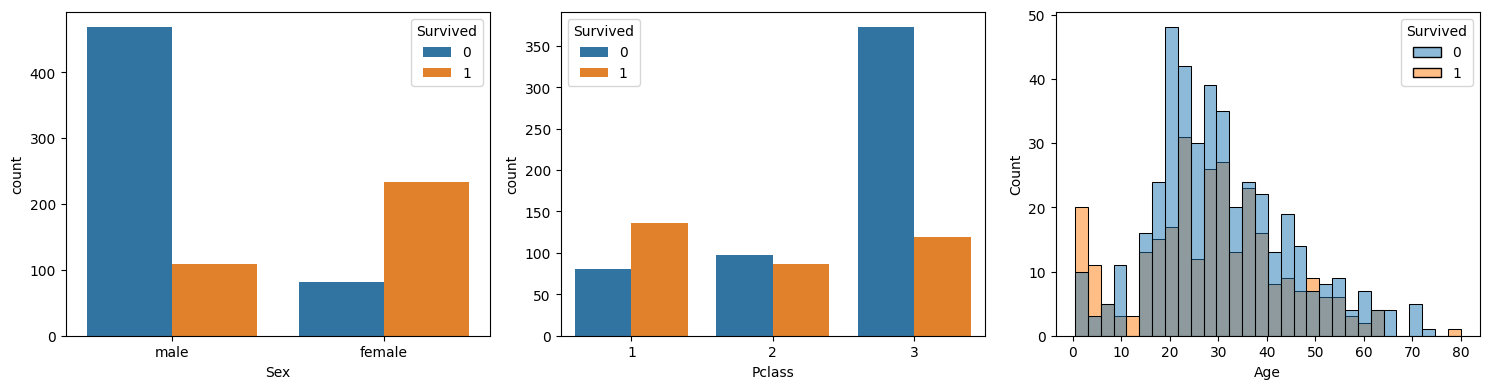

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Sex', hue='Survived', data=df, ax=ax[0])
sns.countplot(x='Pclass', hue='Survived', data=df, ax=ax[1])
sns.histplot(data=df, x='Age', hue='Survived', bins=30, ax=ax[2])
plt.tight_layout()
plt.show()

In [5]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
target = 'Survived'
X = df[features]
y = df[target]
print('Features:', features)
print('Target:', target)

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Target: Survived


In [6]:
num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
cat_cols = ['Sex', 'Embarked']

preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
    ]), cat_cols)
])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('The test set is kept separate so the final evaluation is done on data the model never saw,')
print('giving an unbiased estimate of generalization. Using it during training would cause data leakage.')

Train: (712, 7) | Test: (179, 7)
The test set is kept separate so the final evaluation is done on data the model never saw,
giving an unbiased estimate of generalization. Using it during training would cause data leakage.


In [8]:
model = Pipeline([
    ('prep', preprocess),
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_split=5, random_state=42))
])
model.fit(X_train, y_train)

rf = model.named_steps['rf']
print('Hyperparameters (set before training):')
print('  n_estimators =', rf.n_estimators)
print('  max_depth =', rf.max_depth)
print('  min_samples_split =', rf.min_samples_split)
print('Parameters (learned during training):')
print('  split features/thresholds in', len(rf.estimators_), 'trees; first tree nodes =', rf.estimators_[0].tree_.node_count)
print('  feature_importances_ =', np.round(rf.feature_importances_, 3))

Hyperparameters (set before training):
  n_estimators = 200
  max_depth = 6
  min_samples_split = 5
Parameters (learned during training):
  split features/thresholds in 200 trees; first tree nodes = 77
  feature_importances_ = [0.137 0.133 0.042 0.035 0.206 0.401 0.015 0.01  0.021]


In [9]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print('Confusion Matrix:\n', cm)
print(f'TN={tn} FP={fp} FN={fn} TP={tp}')

test_results = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'Specificity': tn / (tn + fp),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
}
for k, v in test_results.items():
    print(f'{k}: {v:.4f}')

Confusion Matrix:
 [[102   8]
 [ 28  41]]
TN=102 FP=8 FN=28 TP=41
Accuracy: 0.7989
Precision: 0.8367
Recall: 0.5942
Specificity: 0.9273
F1-Score: 0.6949
ROC-AUC: 0.8405


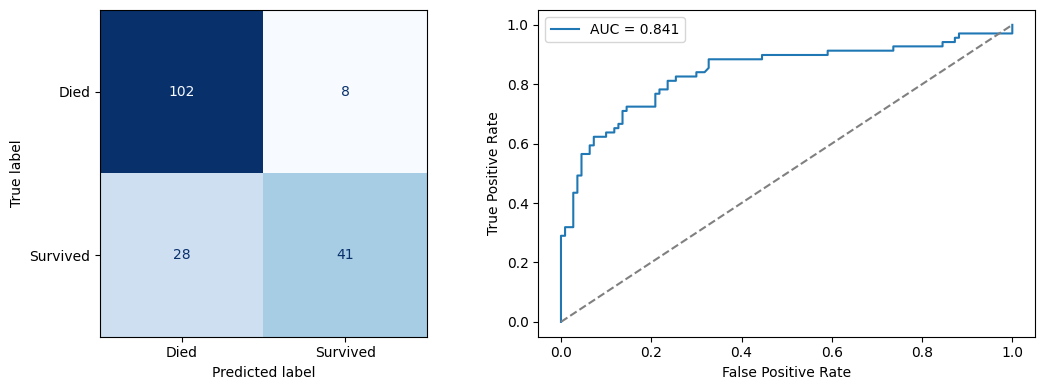

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived']).plot(ax=ax[0], cmap='Blues', colorbar=False)
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_results['ROC-AUC']:.3f}")
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].legend()
plt.tight_layout()
plt.show()

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

kf_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='accuracy')
skf_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy')

print('5-Fold scores:', np.round(kf_scores, 4))
print(f'5-Fold mean = {kf_scores.mean():.4f}, std = {kf_scores.std():.4f}')
print('Stratified 5-Fold scores:', np.round(skf_scores, 4))
print(f'Stratified mean = {skf_scores.mean():.4f}, std = {skf_scores.std():.4f}')

5-Fold scores: [0.7902 0.8042 0.8169 0.838  0.8521]
5-Fold mean = 0.8203, std = 0.0224
Stratified 5-Fold scores: [0.8531 0.7902 0.8521 0.7958 0.8028]
Stratified mean = 0.8188, std = 0.0279


In [12]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_res = cross_validate(model, X_train, y_train, cv=skf, scoring=metrics)

comparison = pd.DataFrame({
    'CV Mean (Stratified)': [cv_res[f'test_{m}'].mean() for m in metrics],
    'CV Std': [cv_res[f'test_{m}'].std() for m in metrics],
    'Test': [test_results['Accuracy'], test_results['Precision'], test_results['Recall'],
             test_results['F1-Score'], test_results['ROC-AUC']],
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
comparison['Gap (Test - CV)'] = comparison['Test'] - comparison['CV Mean (Stratified)']
comparison.round(4)

,CV Mean (Stratified),CV Std,Test,Gap (Test - CV)
Accuracy,0.8188,0.0279,0.7989,-0.0199
Precision,0.8234,0.0535,0.8367,0.0134
Recall,0.6738,0.0467,0.5942,-0.0796
F1-Score,0.7400,0.0413,0.6949,-0.0451
ROC-AUC,0.8761,0.0200,0.8405,-0.0356


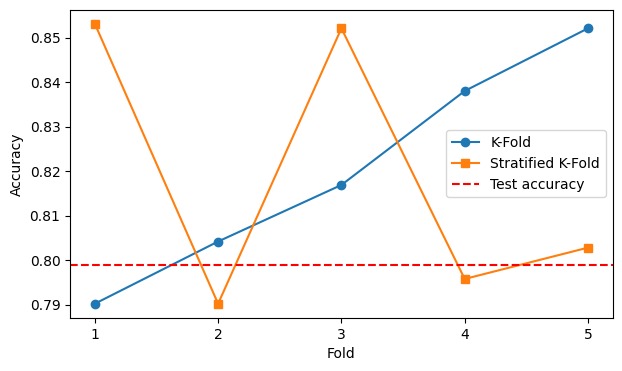

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 6), kf_scores, 'o-', label='K-Fold')
plt.plot(range(1, 6), skf_scores, 's-', label='Stratified K-Fold')
plt.axhline(test_results['Accuracy'], color='red', linestyle='--', label='Test accuracy')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.xticks(range(1, 6))
plt.legend()
plt.show()

In [14]:
gap = abs(test_results['Accuracy'] - skf_scores.mean())
print(f'Stratified CV accuracy: {skf_scores.mean():.4f} +/- {skf_scores.std():.4f}')
print(f'Test accuracy: {test_results["Accuracy"]:.4f} (gap = {gap:.4f})')
if skf_scores.std() < 0.03 and gap < 0.05:
    print('Conclusion: The model is consistent across data splits; fold scores vary little and CV agrees with test performance.')
else:
    print('Conclusion: The model shows noticeable variation across splits or a CV/test gap, so performance is less consistent.')
print('Cross-validation is useful because a single train/test split depends on one random partition;')
print('CV uses every training sample for both training and validation, giving a mean score and a std that')
print('shows stability, which makes the estimate of generalization more reliable.')

Stratified CV accuracy: 0.8188 +/- 0.0279
Test accuracy: 0.7989 (gap = 0.0199)
Conclusion: The model is consistent across data splits; fold scores vary little and CV agrees with test performance.
Cross-validation is useful because a single train/test split depends on one random partition;
CV uses every training sample for both training and validation, giving a mean score and a std that
shows stability, which makes the estimate of generalization more reliable.
